# Phân tích sai số và đóng góp đặc trưng trên validation

**Mục tiêu:** trả lời câu hỏi nghiên cứu 3: mô hình sai nhiều ở khung giờ, ngày lễ hoặc điều kiện thời tiết nào; đồng thời xem đặc trưng nào đóng góp vào dự đoán của mô hình Time + Weather.

Sai số = dự đoán − thực tế; giá trị âm nghĩa là dự đoán thấp hơn thực tế. SHAP mô tả cách mô hình dùng đặc trưng, **không** kết luận quan hệ nhân quả.

**Chạy trước:** `V_3.ipynb` và `V_4.ipynb`. Test giữ riêng.

## 1 · Chuẩn bị dữ liệu và dự đoán

In [1]:
from pathlib import Path
import json
import os
import platform
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import xgboost

# Tìm gốc dự án từ thư mục hiện tại hoặc các thư mục cha.
current_dir = Path.cwd().resolve()
project_dir = next(
    (p for p in (current_dir, *current_dir.parents)
     if (p / "data" / "Metro_Interstate_Traffic_Volume.csv").is_file()),
    None,
)
if project_dir is None:
    raise FileNotFoundError("Không tìm thấy CSV trong thư mục dự án.")
if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))

output_dir = project_dir / "outputs"
figure_dir = project_dir / "figures"
pd.set_option("display.max_columns", None)
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e5e4e0", "axes.axisbelow": True,
    "lines.linewidth": 2,
})
BLUE, ORANGE = "#2a78d6", "#eb6834"

print("Python:", platform.python_version())
print("pandas:", pd.__version__, "| scikit-learn:", sklearn.__version__, "| xgboost:", xgboost.__version__)

Python: 3.13.9
pandas: 3.0.6 | scikit-learn: 1.9.1 | xgboost: 3.4.1


In [2]:
from src.data import load_splits
from src.evaluation import errors_by_group, regression_metrics
from src.features import CONFIG_B, WEATHER_FEATURES, WEATHER_GROUPS, build_features, has_history
from src.models import load_best_params, load_predictions, make_model

features = build_features(load_splits())
train, validation = features["train"], features["validation"]
prediction_b = load_predictions("V_3", output_dir)["B_thoi_tiet|XGBoost"].to_numpy()
history = load_predictions("V_4", output_dir)
mask_c = has_history(validation).to_numpy()
validation_c = validation[mask_c].reset_index(drop=True)
assert history["date_time"].equals(validation_c["date_time"])

prediction_c = history["C_toan_bo_train|XGBoost"].to_numpy()
prediction_b_same_hours = prediction_b[mask_c]
print("B trên toàn validation:", regression_metrics(validation["traffic_volume"], prediction_b))
print("B trên các giờ đủ lịch sử:", regression_metrics(validation_c["traffic_volume"], prediction_b_same_hours))
print("C trên các giờ đủ lịch sử:", regression_metrics(validation_c["traffic_volume"], prediction_c))

B trên toàn validation: {'MAE': 243.45286855077228, 'RMSE': 389.8889539587513, 'R2': 0.9606600488692925}
B trên các giờ đủ lịch sử: {'MAE': 243.04077619834712, 'RMSE': 387.68675017059076, 'R2': 0.9610508367305131}
C trên các giờ đủ lịch sử: {'MAE': 192.93986297520664, 'RMSE': 311.1061969326594, 'R2': 0.974918498085338}


## 2 · Sai số theo giờ trong ngày

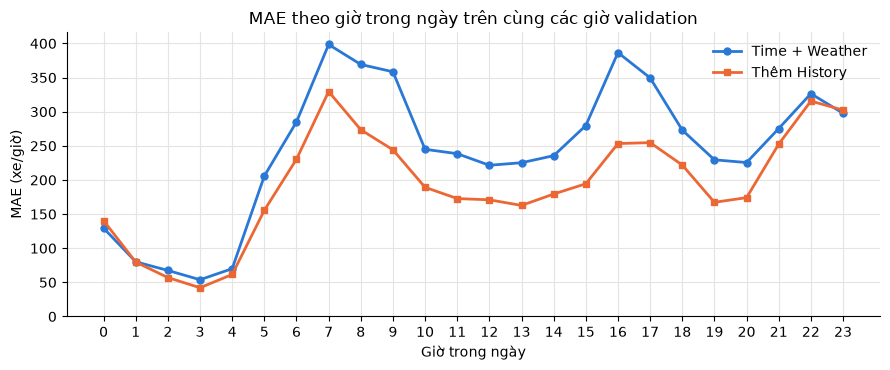

,so_gio,luu_luong_tb,MAE,sai_so_tb,MAE_C,sai_so_tb_C
hour,,,,,,
7,252,4785.9,398.5,-23.5,329.5,58.6
16,251,5761.8,386.6,-184.8,253.4,-56.1
8,252,4638.3,369.2,-8.6,273.6,57.2
9,255,4455.7,358.5,-131.8,244.2,-14.5
17,251,5414.0,349.5,-106.0,254.7,-23.3
22,254,2339.4,326.4,-156.4,315.6,-77.8
23,251,1622.5,297.8,-151.2,302.4,-74.3
6,252,4231.2,285.1,-33.6,230.4,21.7


In [3]:
by_hour_b = errors_by_group(validation_c, validation_c["hour"], prediction_b_same_hours, "hour")
by_hour_c = errors_by_group(validation_c, validation_c["hour"], prediction_c, "hour")

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(by_hour_b.index, by_hour_b["MAE"], color=BLUE, label="Time + Weather", marker="o", markersize=5)
ax.plot(by_hour_c.index, by_hour_c["MAE"], color=ORANGE, label="Thêm History", marker="s", markersize=5)
ax.set(title="MAE theo giờ trong ngày trên cùng các giờ validation", xlabel="Giờ trong ngày",
       ylabel="MAE (xe/giờ)", xticks=range(0, 24), ylim=(0, None))
ax.legend(frameon=False)
plt.tight_layout()
figure_dir.mkdir(exist_ok=True)
plt.savefig(figure_dir / "error_by_hour.png", dpi=150, bbox_inches="tight")
plt.show()

display(by_hour_b.join(by_hour_c[["MAE", "sai_so_tb"]], rsuffix="_C").sort_values("MAE", ascending=False).head(8).round(1))

**Nhận xét**

- Sai số lớn nhất ở giờ cao điểm: 07:00 (398,5 xe/giờ) và 16:00 (386,6) với Time + Weather. Lịch sử giảm mạnh nhất ở 16:00 (còn 253,4) và 08:00–09:00.
- Ở 22:00–23:00, lịch sử gần như không giúp (326,4 → 315,6 và 297,8 → 302,4). Cả hai mô hình đều dự đoán thấp hơn thực tế vào các giờ này.
- 00:00–04:00 có MAE thấp vì lưu lượng thấp. MAE theo giờ phụ thuộc mức lưu lượng, nên không so trực tiếp mức khó giữa ban đêm và ban ngày.

## 3 · Sai số theo loại ngày và theo tháng

In [4]:
day_type = np.select(
    [validation["is_holiday"].eq(1), validation["is_weekend"].eq(1)],
    ["Ngày có nhãn lễ", "Cuối tuần"], default="Ngày làm việc",
)
display(errors_by_group(validation, day_type, prediction_b, "loai_ngay").round(1))

month_table = errors_by_group(validation, validation["date_time"].dt.to_period("M").astype(str), prediction_b, "thang")
display(month_table.round(1))

daily = pd.DataFrame({
    "date": validation["date_time"].dt.normalize(),
    "actual": validation["traffic_volume"],
    "absolute": np.abs(prediction_b - validation["traffic_volume"]),
    "error": prediction_b - validation["traffic_volume"],
    "holiday_name": validation["holiday_name"],
    "weather": validation["weather_main"],
})
worst_days = daily.groupby("date").agg(
    so_gio=("absolute", "size"), MAE=("absolute", "mean"), sai_so_tb=("error", "mean"),
    luu_luong_tb=("actual", "mean"), su_kien=("holiday_name", "first"),
    ty_le_gio_co_tuyet=("weather", lambda v: v.str.contains("snow").mean()),
).query("so_gio >= 12").sort_values("MAE", ascending=False).head(12)
display(worst_days.round(2))
print("Tỷ trọng tổng sai số tuyệt đối của 12 ngày này:",
      f"{daily.loc[daily['date'].isin(worst_days.index), 'absolute'].sum() / daily['absolute'].sum():.1%}",
      "| trên số ngày:", daily["date"].nunique())

,so_gio,luu_luong_tb,MAE,sai_so_tb
loai_ngay,,,,
Cuối tuần,1722,2743.2,267.6,-153.3
Ngày có nhãn lễ,240,2618.1,586.7,-34.7
Ngày làm việc,4124,3661.6,213.4,-56.3


,so_gio,luu_luong_tb,MAE,sai_so_tb
thang,,,,
2017-05,523,3383.8,195.0,33.1
2017-06,720,3446.9,187.7,40.0
2017-07,738,3299.5,255.5,-136.3
2017-08,743,3517.1,205.6,-126.8
2017-09,716,3455.8,230.1,-146.9
2017-10,744,3472.1,216.0,-133.5
2017-11,716,3368.5,307.7,-155.6
2017-12,740,3125.3,332.8,-75.8
2018-01,446,3073.6,249.1,36.5


,so_gio,MAE,sai_so_tb,luu_luong_tb,su_kien,ty_le_gio_co_tuyet
date,,,,,,
2017-11-10,24,1243.77,-1233.04,3706.92,Veterans Day,0.17
2017-11-24,24,944.46,881.42,2757.21,None,0.00
2018-01-01,24,801.53,575.30,1749.33,New Years Day,0.00
2017-11-23,24,763.31,645.66,2052.96,Thanksgiving Day,0.00
2017-08-24,24,741.68,-649.98,3892.38,State Fair,0.00
2018-01-11,24,735.02,702.77,2736.71,None,0.62
2017-12-05,21,700.45,667.38,2380.29,None,0.52
2017-07-03,24,693.94,568.73,2893.79,None,0.00
2017-12-02,24,589.28,-557.53,3348.42,None,0.00


Tỷ trọng tổng sai số tuyệt đối của 12 ngày này: 14.2% | trên số ngày: 255


**Nhận xét**

- Giờ ngày lễ có MAE 586,7, gấp khoảng 2,7 lần ngày làm việc (213,4). Cuối tuần có MAE 267,6 và bị dự đoán thấp trung bình 153,3 xe/giờ.
- Từ 07/2017 đến 11/2017, sai số trung bình âm khoảng 127–156 xe/giờ: mô hình dự đoán thấp liên tục. Lưu lượng năm 2017 cao hơn các năm train, nên mô hình chỉ dựa vào thời gian chưa theo kịp mức chung; lịch sử giúp bù phần này.
- 12 ngày sai nhiều nhất (4,7% số ngày) chiếm 14,2% tổng sai số tuyệt đối. Nhóm này gồm ngày lễ có hành vi khác thường (Veterans Day nghỉ bù, State Fair), ngày sát lễ không có nhãn (24/11/2017 sau Thanksgiving, 03/07 và 26/12/2017) và ngày có tuyết ở ít nhất một nửa số giờ (28/12/2017, 11/01/2018, 05/12/2017).
- Hướng cải thiện có căn cứ: đặc trưng ngày sát lễ, kỳ nghỉ cuối năm và loại lễ. Các thông tin này biết trước nên vẫn dùng được cho demo.

## 4 · Sai số theo điều kiện thời tiết

Các nhóm chồng lấp vì một giờ có thể mang nhiều nhãn. Hình ghi số giờ của từng nhóm; nhóm `smoke` chỉ có một giờ nên không đưa vào hình.

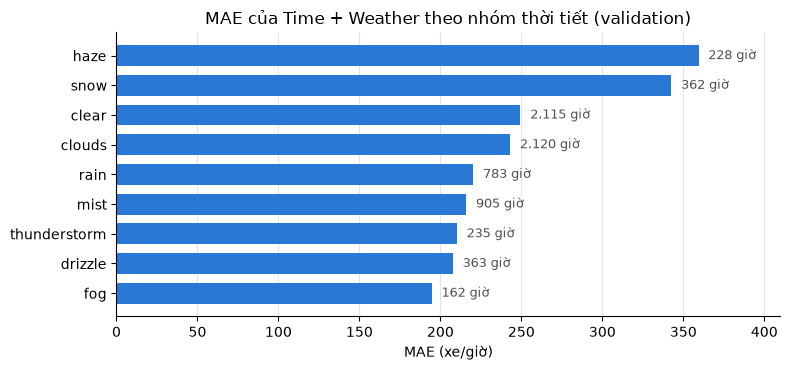

,nhom,so_gio,MAE,RMSE,sai_so_tb,luu_luong_tb
4,haze,228,359.4,530.4,-98.1,3297.8
8,snow,362,342.6,497.6,-44.4,3259.7
0,clear,2115,249.5,434.1,-50.7,2914.6
1,clouds,2120,243.1,359.2,-122.3,3954.3
6,rain,783,220.3,334.9,-54.6,3417.3
5,mist,905,215.9,342.5,-69.2,3011.6
9,thunderstorm,235,210.2,312.6,-36.6,3137.9
2,drizzle,363,207.7,321.5,-64.4,3375.1
3,fog,162,194.7,311.4,-129.5,3097.2
7,smoke,1,10.6,10.6,10.6,5952.0


In [5]:
rows = []
for name in WEATHER_GROUPS:
    mask = validation[f"weather_{name}"].eq(1).to_numpy()
    if mask.any():
        part = validation[mask]
        rows.append({"nhom": name, "so_gio": int(mask.sum()),
                     "MAE": np.abs(prediction_b[mask] - part["traffic_volume"]).mean(),
                     "RMSE": np.sqrt(((prediction_b[mask] - part["traffic_volume"]) ** 2).mean()),
                     "sai_so_tb": (prediction_b[mask] - part["traffic_volume"]).mean(),
                     "luu_luong_tb": part["traffic_volume"].mean()})
weather_errors = pd.DataFrame(rows).sort_values("MAE")
plotted = weather_errors[weather_errors["so_gio"].ge(30)]

fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.barh(plotted["nhom"], plotted["MAE"], color=BLUE, height=0.7)
for bar, n in zip(bars, plotted["so_gio"]):
    ax.text(bar.get_width() + 6, bar.get_y() + bar.get_height() / 2, f"{n:,} giờ".replace(",", "."),
            va="center", fontsize=9, color="#52514e")
ax.set(title="MAE của Time + Weather theo nhóm thời tiết (validation)", xlabel="MAE (xe/giờ)")
ax.grid(axis="y", visible=False)
ax.margins(x=0.14)
plt.tight_layout()
plt.savefig(figure_dir / "error_by_weather.png", dpi=150, bbox_inches="tight")
plt.show()
display(weather_errors.sort_values("MAE", ascending=False).round(1))

**Nhận xét**

- `haze` (228 giờ) và `snow` (362 giờ) có MAE cao nhất, lần lượt 359,4 và 342,6. `fog`, `drizzle` và `thunderstorm` có MAE thấp hơn trung bình.
- Mọi nhóm đều có sai số trung bình âm, phù hợp với xu hướng dự đoán thấp của giai đoạn 2017.
- Các nhóm chồng lấp và khác nhau về mùa, giờ trong ngày, nên bảng này mô tả nơi mô hình sai, chưa tách được ảnh hưởng riêng của thời tiết.

## 5 · Một số đoạn dự đoán cụ thể

Một tuần không có ngày lễ và tuần chứa ngày sai nhiều nhất trong validation. Đường bị ngắt tại các giờ không có dữ liệu.

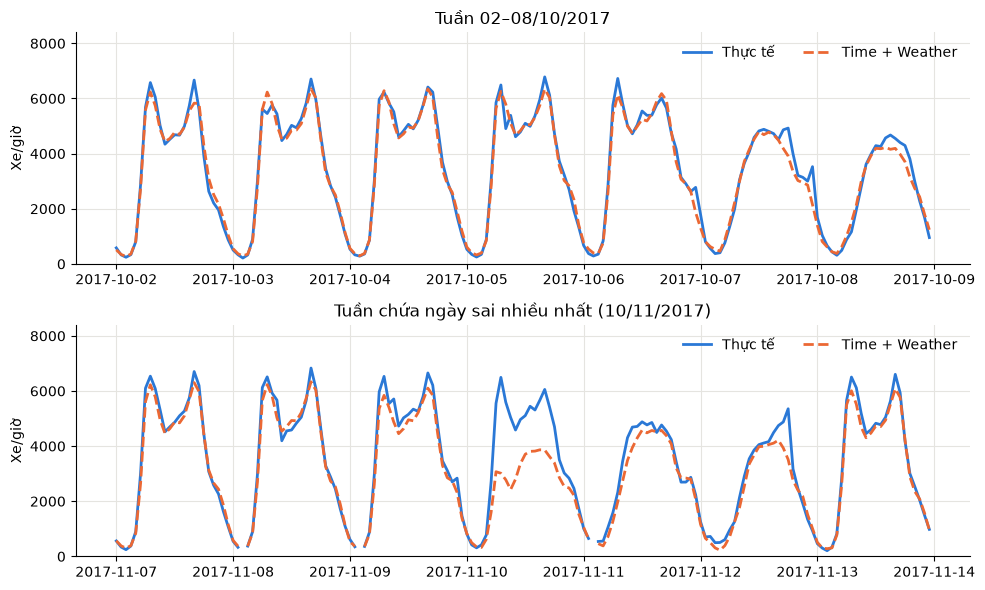

In [6]:
worst_day = worst_days.index[0]
windows = [
    ("Tuần 02–08/10/2017", pd.Timestamp("2017-10-02"), pd.Timestamp("2017-10-09")),
    (f"Tuần chứa ngày sai nhiều nhất ({worst_day:%d/%m/%Y})",
     worst_day - pd.Timedelta(days=3), worst_day + pd.Timedelta(days=4)),
]
fig, axes = plt.subplots(2, 1, figsize=(10, 6))
for ax, (title, start, end) in zip(axes, windows):
    mask = validation["date_time"].between(start, end, inclusive="left").to_numpy()
    times = validation.loc[mask, "date_time"]
    frame = pd.DataFrame({"actual": validation.loc[mask, "traffic_volume"].to_numpy(),
                          "pred": prediction_b[mask]}, index=times).asfreq("h")
    ax.plot(frame.index, frame["actual"], color=BLUE, label="Thực tế")
    ax.plot(frame.index, frame["pred"], color=ORANGE, label="Time + Weather", linestyle="--")
    ax.set(title=title, ylabel="Xe/giờ", ylim=(0, 8400))
    ax.legend(frameon=False, ncols=2, loc="upper right")
plt.tight_layout()
plt.savefig(figure_dir / "actual_vs_predicted_weeks.png", dpi=150, bbox_inches="tight")
plt.show()

## 6 · Đóng góp đặc trưng bằng SHAP

Dùng giá trị SHAP do XGBoost tính trực tiếp (`pred_contribs=True`), không cần cài thêm thư viện `shap`. Mô hình XGBoost cấu hình B dùng tham số đã chọn trong V_3, fit trên train và giải thích các giờ validation. Các cột cùng nguồn như `hour`, `hour_sin`, `hour_cos` chia sẻ đóng góp cho nhau nên phần tổng hợp theo nhóm dễ diễn giải hơn từng cột.

,mean_abs_shap,ty_trong_%
Giờ,1574.300049,73.599998
Thứ,366.700012,17.100000
Tháng,73.199997,3.400000
Thời tiết,68.599998,3.200000
Ngày lễ,56.200001,2.600000


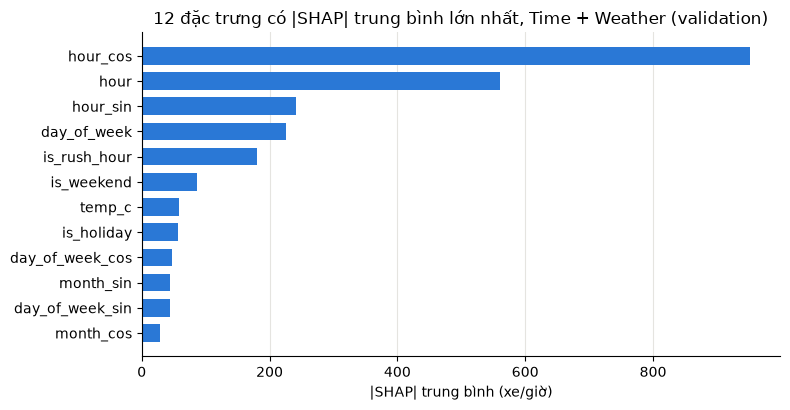

,mean_abs_shap
hour_cos,951.099976
hour,560.700012
hour_sin,240.699997
day_of_week,225.300003
is_rush_hour,180.699997
is_weekend,86.800003
temp_c,58.099998
is_holiday,56.200001
day_of_week_cos,47.200001
month_sin,44.400002


In [7]:
best_params = load_best_params("V_3", output_dir)["B_thoi_tiet|XGBoost"]
model = make_model("XGBoost", CONFIG_B).set_params(**best_params)
model.fit(train[CONFIG_B], train["traffic_volume"])
assert np.allclose(np.clip(model.predict(validation[CONFIG_B]), 0, None), prediction_b, atol=0.01)

contributions = model.get_booster().predict(
    xgboost.DMatrix(validation[CONFIG_B], feature_names=CONFIG_B), pred_contribs=True
)
# Tổng đóng góp cộng giá trị nền phải bằng dự đoán.
assert np.allclose(contributions.sum(axis=1), model.predict(validation[CONFIG_B]), atol=0.05)

shap_values = pd.DataFrame(contributions[:, :-1], columns=CONFIG_B)
importance = shap_values.abs().mean().sort_values(ascending=False).rename("mean_abs_shap")

def feature_group(column):
    if column in WEATHER_FEATURES:
        return "Thời tiết"
    if column == "is_holiday":
        return "Ngày lễ"
    if column.startswith("hour") or column == "is_rush_hour":
        return "Giờ"
    if column.startswith("day_of_week") or column == "is_weekend":
        return "Thứ"
    return "Tháng"

groups = shap_values.T.groupby(feature_group).sum().T.abs().mean().sort_values(ascending=False)
group_table = pd.DataFrame({"mean_abs_shap": groups, "ty_trong_%": 100 * groups / groups.sum()})
display(group_table.round(1))

top = importance.head(12).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(top.index, top.to_numpy(), color=BLUE, height=0.7)
ax.set(title="12 đặc trưng có |SHAP| trung bình lớn nhất, Time + Weather (validation)",
       xlabel="|SHAP| trung bình (xe/giờ)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.savefig(figure_dir / "shap_time_weather.png", dpi=150, bbox_inches="tight")
plt.show()

importance.to_csv(output_dir / "metrics" / "shap_time_weather.csv")
display(importance.head(12).round(1).to_frame())

**Nhận xét**

- Nhóm giờ chiếm 73,6% tổng |SHAP| trung bình, thứ chiếm 17,1%; tháng, thời tiết và ngày lễ lần lượt 3,4%, 3,2% và 2,6%.
- `temp_c` là đặc trưng thời tiết có đóng góp lớn nhất (58,1 xe/giờ). Tỷ trọng nhỏ của thời tiết phù hợp với kết quả đối chứng A–B của V_3.
- `is_holiday` có |SHAP| trung bình thấp vì chỉ khác 0 ở ít giờ, dù tác động trên từng giờ lễ lớn. |SHAP| trung bình đo mức sử dụng trung bình, không đo tầm quan trọng trong từng tình huống.
- `temp_c` và `month` cùng mang thông tin mùa, nên đóng góp có thể chia giữa hai cột. SHAP mô tả mô hình, không chứng minh quan hệ nhân quả.

### Tóm tắt cho câu hỏi nghiên cứu 3

| Nơi sai nhiều | Bằng chứng | Hướng xử lý |
|---|---|---|
| Giờ cao điểm 07:00, 16:00 | MAE gần 400 xe/giờ | Lịch sử giảm còn khoảng 250–330 |
| Ngày lễ và ngày sát lễ | MAE giờ lễ 586,7; 8/12 ngày sai nhất là ngày lễ hoặc sát lễ | Loại lễ, ngày sát lễ, kỳ nghỉ cuối năm |
| Giai đoạn 07–11/2017 | Dự đoán thấp liên tục 127–156 xe/giờ | Lịch sử, hoặc đặc trưng xu hướng theo năm |
| Ngày tuyết, haze | MAE 342,6 và 359,4 | Thêm dữ liệu mùa đông; kiểm tra lại với test |

Các kết quả trên là validation. Test vẫn giữ riêng cho V_5.